# Hierarchical Clustering - UPGMA

---
## Learning Objectives

1. Implement a distance-based phylogeny neighbor joining algorithm
1. Understanding of hierarchical clustering
1. Manipulation of arrays and lists in Python


---
## Imports
You will need to install a two new packages to properly render your phylogenetic trees. Using your preferred package manager, install both [`biopython`](https://biopython.org/) and `matplotlib` into your virtual environments.

For example:
```bash
$ micromamba create -n module06 -c bioconda -c conda-forge python numpy matplotlib biopython
```

In [5]:
from typing import List, Tuple, Dict
from io import StringIO
import matplotlib.pyplot as plt
from Bio import Phylo
import numpy as np

---
## Background

Today we will implement a distance-based phylogenetic tree construction method using the Neighbor-Joining (NJ) algorithm and Smith-Waterman local alignment scores. Unlike UPGMA (Unweighted Pair Group Method using Arithmetic averages), NJ produces unrooted trees and does not assume a constant evolutionary rate across lineages, making it more biologically realistic for analyzing sequence relationships.

We will use HIV-1 reverse transcriptase sequences to construct our phylogenetic tree. The Smith-Waterman algorithm will be used to generate pairwise local alignment scores, which will then be converted into distances for tree construction. This approach is particularly suitable for HIV sequence analysis as it:
1. Handles sequence variations effectively through local alignment
2. Accounts for potential rate heterogeneity across different viral strains
3. Does not assume a molecular clock

The ultimate output will be an unrooted phylogenetic tree representing the evolutionary relationships between the HIV-1 sequences, visualized using the ete3 library. This method provides insights into viral diversity and evolutionary patterns while avoiding the assumptions of simpler hierarchical clustering approaches.

The key innovations of this implementation are:
- Use of Smith-Waterman for sensitive local alignment scoring
- Implementation of Neighbor-Joining for unrooted tree construction
- More biologically realistic evolutionary model

## Neighbor-Joining Algorithm

**Input**: Distance matrix $D$ for $n$ sequences

**Initialization**:
- Let $n$ be the number of sequences
- Assign each sequence $i$ to its own leaf node
- Initialize tree $T$ with leaf nodes

**Iteration**:
While $n > 2$:
1. Calculate Q-matrix where:
   $Q(i,j) = (n-2)d(i,j) - \sum_{k=1}^n d(i,k) - \sum_{k=1}^n d(j,k)$

2. Find pair $(i,j)$ with minimum $Q(i,j)$

3. Calculate branch lengths:
   $d_i = \frac{d(i,j) + (r_i - r_j)/(n-2)}{2}$
   $d_j = d(i,j) - d_i$
   where $r_i = \sum_{k=1}^n d(i,k)$

4. Create new node $k$
   - Add branches from $k$ to $i$ and $j$ with lengths $d_i$ and $d_j$

5. Update distances to remaining nodes $x$:
   $d(k,x) = \frac{d(i,x) + d(j,x) - d(i,j)}{2}$

6. Remove nodes $i$ and $j$
7. Add node $k$ to active nodes
8. $n = n - 1$

**Termination**:
When $n = 2$ with remaining nodes $i$ and $j$:
- Add final branch between $i$ and $j$ with length $d(i,j)$
- Return unrooted tree $T$

---
## Distance metrics for comparing sequences

### Smith-Waterman
This was previously implemented. Feel free to import if you know how...or Copy & Paste.



In [6]:
def read_fasta(filename: str) -> Dict[str, str]:
    """Reads sequences from FASTA file.

    Args:
        filename (str): Path to FASTA file containing HIV RT sequences

    Returns:
        Dict[str, str]: Dictionary mapping sequence IDs to sequences

    Examples:
        seqs = read_fasta("lafayette_SARS_RT.fasta")
        len(seqs) > 0
        True
    """
    with open(filename, 'r') as fa:
        #Initialize header, sequence list, and sequence dictionary.
        header = next(fa).strip()[1:]
        seq_list = []
        seqs_dict = {}

        #Loop through every line and store header and sequence as key value pairs in dictionary
        for line in fa:
            if line.startswith('>'):
                seq = ''.join(seq_list)
                seqs_dict[header] = seq
                header = line.strip()[1:]
                seq_list = []
            else:
                seq_list.append(line.strip())

        #Store last sequence and header in dictionary and return it
        seqs_dict[header] = ''.join(seq_list)
        return seqs_dict

In [7]:
def smith_waterman(
    sequence1: str,
    sequence2: str,
    match_score: float = 2.0,
    mismatch_penalty: float = -1.0,
    gap_penalty: float = -1.0
) -> float:
    """Implements Smith-Waterman local alignment algorithm.

    Args:
        sequence1 (str): First HIV RT sequence
        sequence2 (str): Second HIV RT sequence
        match_score (float): Score for matching characters
        mismatch_penalty (float): Penalty for mismatched characters
        gap_penalty (float): Penalty for gaps

    Returns:
        float: Normalized similarity score between sequences

    Examples:
        >>> seq1 = "ACGT"
        >>> seq2 = "ACGT"
        >>> smith_waterman(seq1, seq2)
        1.0
    """
    matrix = np.zeros((len(sequence1) + 1, len(sequence2) + 1))
    for row, base1 in enumerate(sequence1, 1):
        for col, base2 in enumerate(sequence2, 1):
            matrix[row, col] = max(
                0,
                matrix[row-1, col-1] + (match_score if base1 == base2 else mismatch_penalty),
                matrix[row-1, col] + gap_penalty,
                matrix[row, col-1] + gap_penalty,
            )
    return matrix.max() / (match_score * len(sequence1))

In [8]:
def build_distance_matrix(sequences: Dict[str, str]) -> Tuple[np.ndarray, List[str]]:
    """Builds DISTANCE (not similiarity) matrix using Smith-Waterman scores.

    Args:
        sequences (Dict[str, str]): Dictionary of HIV RT sequences

    Returns:
        Tuple[np.ndarray, List[str]]: Distance matrix and list of sequence IDs

    Examples:
        seqs = read_fasta("lafayette_SARS_RT.fasta")
        mat, ids = build_distance_matrix(seqs)
        mat[0:3, 0:3]  # Show 3x3 slice of distance matrix
        array([[0.000, 0.004, 0.012],
              [0.004, 0.000, 0.012],
              [0.012, 0.012, 0.000]])
        len(ids)  # Number of sequences
        19
    """
    ids = list(sequences.keys())
    seqs = list(sequences.values())
    sequence_matrix = np.zeros((len(seqs), len(seqs)))

    #Replace every zero with its score
    for row in range(len(seqs)):
        for col in range(len(seqs)):
            sequence_matrix[row, col] = 1 - smith_waterman(seqs[row], seqs[col])
    return sequence_matrix, ids

[[0.         0.00655022 0.04585153]
 [0.00655022 0.         0.03930131]
 [0.04585153 0.03930131 0.        ]]


20

In [37]:
def neighbor_joining(
    distance_matrix: np.ndarray,
    labels: List[str]
) -> str:
    """Implements Neighbor-Joining algorithm for phylogenetic tree construction.

    Args:
        distance_matrix (np.ndarray): Distance matrix from Smith-Waterman scores
        labels (List[str]): Sequence identifiers

    Returns:
        str: Newick format tree string

    Examples:
        seqs = read_fasta("lafayette_SARS_RT.fasta")
        mat, ids = build_distance_matrix(seqs)
        tree = neighbor_joining(mat, ids)
        tree.startswith("((DM1:0.002,DM2:0.002)")  # Start of Newick string
        True
        tree.count(",")  # Number of separators in tree
        18
    """
    #Copy matrix to avoid destruction of original, increases the memory usage heavily, so remove if needed.
    copy_distance_matrix = np.copy(distance_matrix)

    #Extract node names from labels list by removing extra information
    node_names = [name.split(' ')[-1] for name in labels]
    num_nodes = len(node_names)

    #Loop through the nodes while the matrix shape is more than 2x2
    while num_nodes > 2:
        #Sum rows from original matrix
        row_sums = np.sum(copy_distance_matrix, axis=1)
        #Calculate first D* iteration. array.reshape turns row_sums from a 1d array to a 2d array with 1 row in it to prevent calculation
        #from failing
        d_star = (num_nodes - 2) * copy_distance_matrix - row_sums.reshape([-1,1]) - row_sums.reshape([1,-1])

        #np.fill_diagonal replaces the zeros in the diagonal with a very large number. That way the min function never picks the diagonal.
        np.fill_diagonal(d_star, 100000000)

        #Min function to pick lowest value in matrix. np.where returns tuple of indices (row and column index) for every position
        #where the value is equal to the minimum. the second line only picks one of the positions.
        row, col = np.where(d_star==d_star.min())
        row, col = (int(row[0]), int(col[0]))

        #Calculate delta between nodes, and limb lengths. Then create a new label for the new branch using newick tree string format
        #Eg. DM1 and DM2 become (DM1:distance1,DM2:distance2)
        delta_nodes = (row_sums[row] - row_sums[col]) / (num_nodes - 2)
        first_limb = (copy_distance_matrix[row,col] + delta_nodes) / 2
        second_limb = copy_distance_matrix[row,col] - first_limb
        new_label = f'({node_names[row]}:{first_limb},{node_names[col]}:{second_limb})'

        #Calculate the distances between the new node created above with the rest of the matrix. then add the new distances to the matrix.
        new_distances = (copy_distance_matrix[row,:] + copy_distance_matrix[:,col] - copy_distance_matrix[row,col]) / 2

        #The np.stack function adds a new column or row to the matrix. the v or h in front stands for vertical (col) or horizontal (row).
        copy_distance_matrix = np.vstack([copy_distance_matrix, new_distances])
        copy_distance_matrix = np.hstack([copy_distance_matrix, np.append(new_distances, 0.0).reshape(-1, 1)])

        #Delete the nodes that have already been merged from the matrix
        copy_distance_matrix = np.delete(copy_distance_matrix, [row, col], axis = 0)
        copy_distance_matrix = np.delete(copy_distance_matrix, [row, col], axis = 1)

        #Append the new name to the list, then remove the old names from the list based on index
        node_names.append(new_label)
        node_names = [name for i, name in enumerate(node_names) if i not in (row, col)]

        #Subtract 1 from the number of nodes (we collapsed 2 nodes into 1 removing 1 node in the process). Repeat process for all
        #iterations
        num_nodes -= 1

    #Produce the final string that will be returned. Careful that the distances have to be manually calculated here.
    final_newick_string = f'{node_names[0]}:{copy_distance_matrix[0,1]/2},{node_names[-1]}:{copy_distance_matrix[1,0]/2}'
    return final_newick_string



In [33]:
def plot_tree(newick_tree: str) -> None:
    """Plots a phylogenetic tree from a Newick string using Biopython and Matplotlib.

    The tree is rendered in a rectangular layout with smaller leaf labels and
    added margins to reduce overlap between labels and branches.

    Args:
        newick_tree (str): Tree in Newick format

    Returns:
        None: Displays the plotted tree
    """
    handle = StringIO(newick_tree)
    tree = Phylo.read(handle, "newick")

    fig, ax = plt.subplots(figsize=(8, 10))

    Phylo.draw(
        tree,
        axes=ax,
        do_show=False,
        label_func=lambda clade: clade.name if clade.is_terminal() else None,
    )
    for text in ax.texts:
        text.set_fontsize(6)              # shrink labels
    ax.margins(x=0.1, y=0.05)             # extra padding around tree

    plt.tight_layout()
    plt.show()


(P6:0.02781710562227075,((P5:0.05730872452692866,P12:0.021293895560407547):0.0034400018195051042,(((P10:0.0002605200476379762,P13:0.012839916633584761):0.011083818534691873,(P3:0.0020605895196506383,P15:0.02414028384279473):0.0020166181465308373):0.004980895196506562,(P8:0.008242358078602612,(DM1:0.006550218340611327,DM2:-1.3877787807814457e-17):0.017958515283842808):0.000750545851528393):0.004611308224163033):0.002204728438864618):0.00018123976528385335,(P9:0.024473765010917012,((P11:0.04733162579778301,((JT1:0.0,JT2:0.0):0.009054713588492169,DM3:0.004045723092730569):0.011620339267719146):0.019636033998752342,(P7:0.04930574508733624,(P2:0.040490486587648165,(P1:0.07674672489082968,(P4:0.03322871179039301,P14:0.07812499999999999):0.007314410480349365):0.0075444479101684295):0.017015215611353697):0.0032214987523393745):0.004558713155021828):0.00018123976528385335


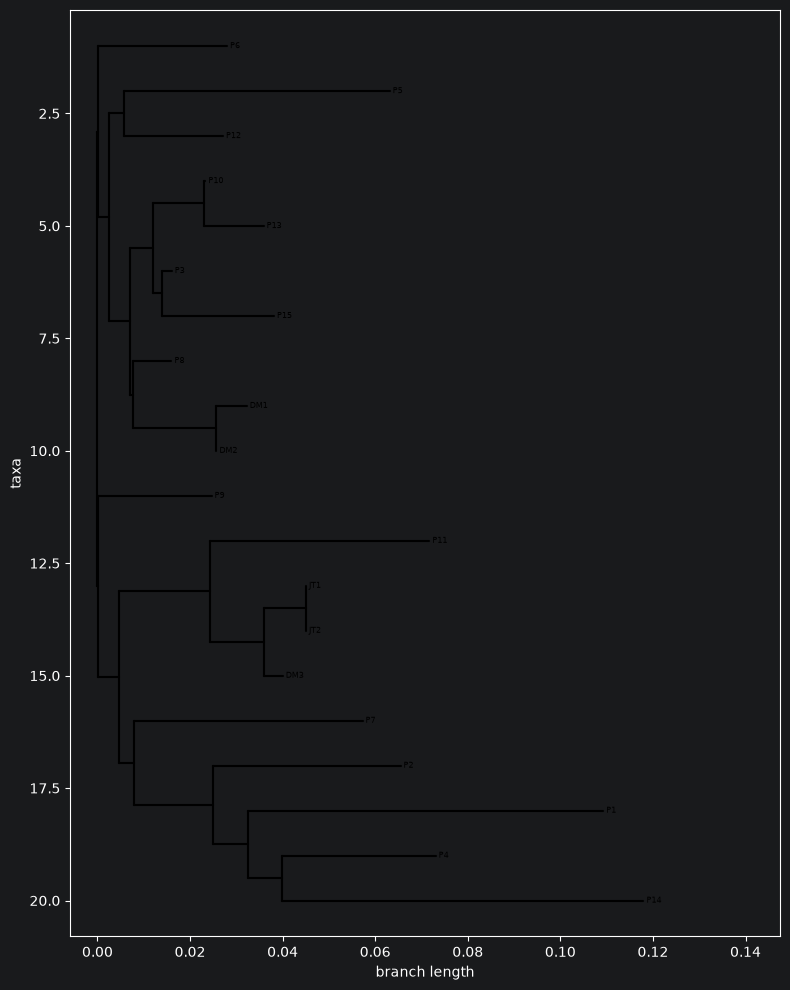

In [38]:
if __name__ == "__main__":
    # Read HIV RT sequences
    sequences = read_fasta("data/lafayette_SARS_RT.fasta")
    
    # Build distance matrix using Smith-Waterman
    dist_matrix, seq_ids = build_distance_matrix(sequences)
    
    # Generate unrooted tree using Neighbor-Joining
    tree = neighbor_joining(dist_matrix, seq_ids)
    print(tree)
    # Plot tree
    plot_tree(tree)